# Error analysis across model systems: routine versus unusual congestion

Extend the recurrent/non-recurrent analysis in the root `error_analysis.ipynb` to saved **Random Forest, transformer, and 29-feature boosted-tree** validation probabilities. No model is retrained and the final July–December 2025 holdout is not opened.

The timetable baseline is each fold's training-only `typical_congestion_30`. Recurrence is measured **15 minutes before onset**: non-recurrent <10%, occasional 10–<40%, recurrent ≥40%. Unusual timing does not imply an incident or establish a congestion cause.

Each model is aligned on station/timestamp keys and checked against the exact shared outcome flags. Two retrospective development policies maximize onsets caught ≥15 minutes ahead under **20 false-warning episodes/day** or **4 wrong-alert hours/day**. Thresholds use an exact score-breakpoint sweep, not binary search: episode counts need not be monotone. Ties favor shorter wrong-alert duration, fewer episodes, then the higher threshold.

**Input availability:** completed run exports are detected automatically. Use the input-path settings to select a specific run. Missing exports are reported as pending; subgroup results are never inferred from summary scores.

## Completed matched-budget comparison: all three 29-feature models

All three saved prediction sets align on **2,898,000 validation rows from 46 stations**, including identical keys and outcome flags. Recomputed quarterly AP agrees with the current fold CSVs. The boosted-tree manifest also matches the Random Forest feature names, shared-code hash, fold settings, and per-fold training counts.

There are **9,293 onset episodes**. Of these, 9,253 have recurrence context, including 1,308 non-recurrent onsets. Global catch rates include all onsets; unusual-jam rates use those 1,308 classified events.

| Budget | Model | All onsets caught ≥15 min early | Non-recurrent onsets caught | False episodes/day | Wrong-alert hours/day |
|---|---|---:|---:|---:|---:|
| 20 false episodes/day | Boosted trees (29) | 46.2% | 1.6% | 20.00 | 2.71 |
| 20 false episodes/day | Transformer | 50.3% | 3.7% | 20.00 | 3.03 |
| 20 false episodes/day | Random Forest | 26.4% | 0.0% | 19.99 | 2.31 |
| 4 wrong-alert hours/day | Boosted trees (29) | 57.2% | 3.9% | 26.56 | 4.00 |
| 4 wrong-alert hours/day | Transformer | 57.9% | 6.1% | 24.34 | 4.00 |
| 4 wrong-alert hours/day | Random Forest | 48.3% | 1.8% | 28.30 | 4.00 |

**Measured conclusion.** Transformer detects the most onsets at both selected budgets, followed by boosted trees, then Random Forest. The transformer–boosted-tree duration-budget gap is only about **0.7 percentage points** (57.9% vs 57.2%); the episode-budget gap is about **4.1 points** (50.3% vs 46.2%). These are descriptive development differences, not evidence of statistical significance.

**Non-recurrent congestion remains the main weakness.** Transformer catches 3.7%/6.1% of unusual onsets under the episode/duration policies, boosted trees 1.6%/3.9%, and Random Forest 0.0%/1.8%. The models largely miss unusual congestion at least 15 minutes ahead under these budgets. Non-recurrent means historically unusual at a station and time, not incident-caused.

**Ranking and early event warning are different.** Boosted trees have the highest mean AP in the current team table, while transformer leads the early episode-detection policies tested here. Random Forest even has slightly higher non-recurrent row AP than transformer, despite detecting fewer unusual episodes early. AP and early warning should both be reported.

**The cost definition matters.** At the episode budget the timetable catches more overall than any learned model (57.6%) but spends about 10.07 wrong-alert hours/day. At the duration budget transformer and boosted trees substantially outperform the timetable (33.6%). At 4 hours/day the transformer also raises fewer false-warning episodes than boosted trees (24.34 vs 26.56) and Random Forest (28.30).

The notebook includes recurrence, station/time, warning-condition, and shared event close-ups for all three models. Case studies use the duration-budget policy and are selected from Random Forest outcomes, not as an unbiased performance sample for other models.

Thresholds were selected and reported on pooled development predictions. Confirm the policy using later-quarter threshold validation before final model selection. No models were retrained, no team summary was changed, and no final-holdout data was used.


In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import sys
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "safeflow_features.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start within the SafeFlow project")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from IPython.display import display
import safeflow_features as sf
from src.random_forest import random_forest_training as training
from src.analysis.early_warning_errors import align_predictions, ExactWarningSweep, warning_leads

RF_INPUT = None  # None = latest completed full Random Forest run
TRANSFORMER_INPUT = None  # run folder containing six prediction Parquets, or one combined prediction Parquet
BOOSTED_INPUT = None  # latest completed boosted-tree run, or legacy combined export
BOOSTED_PROBABILITY_COLUMN = None  # inferred from the export schema unless specified
EPISODE_BUDGET, HOURS_BUDGET = 20, 4
RECURRENCE_CUTS = [0.10, 0.40]
GROUPS = ["non-recurrent", "occasional", "recurrent"]
N_MISSED_EXAMPLES, N_CAUGHT_EXAMPLES = 2, 2
OUT = ROOT / "results" / "error_analysis_models" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT.mkdir(parents=True, exist_ok=False)
CACHE_DIR = OUT.parent / "cache"
CACHE_DIR.mkdir(exist_ok=True)
(OUT.parent / ".gitignore").write_text("cache/\n", encoding="utf-8")
COLORS = {"Timetable": "#64748b", "Random Forest": "#3279ac", "Transformer": "#8b5cc2", "Boosted trees (29)": "#188a77"}
GROUP_COLORS = {"non-recurrent": "#db7046", "occasional": "#d9a032", "recurrent": "#1b9b80"}

def completed_rf():
    candidates=[]
    for file in (ROOT / "src" / "random_forest" / "results").glob("*full*/manifest.json"):
        info=json.loads(file.read_text(encoding="utf-8"))
        if info.get("status")=="complete" and len(info.get("completed_fold_names",[]))==6:
            candidates.append(file.parent)
    if not candidates:
        raise FileNotFoundError("No completed full Random Forest run found")
    return sorted(candidates)[-1]
rf_dir = Path(RF_INPUT) if RF_INPUT is not None else completed_rf()
rf_manifest = json.loads((rf_dir / "manifest.json").read_text(encoding="utf-8"))
shared_hash=hashlib.sha256(Path(sf.__file__).read_bytes()).hexdigest()
if shared_hash != rf_manifest["shared_code_sha256"]:
    raise ValueError("The shared module changed since the RF run; audit the feature/label contract before comparing")
assert len(sf.SHARED_FEATURES)==29 and list(sf.SHARED_FEATURES)==rf_manifest["features"]

def prediction_files(path):
    path=Path(path)
    files=[path] if path.is_file() else sorted(path.glob("*/validation_predictions.parquet"))
    if not files:
        raise FileNotFoundError(f"No validation prediction files at {path}")
    return files

if TRANSFORMER_INPUT is None:
    candidates=[p for p in (ROOT / "src" / "transformer" / "results").glob("*")
                if p.is_dir() and len(list(p.glob("*/validation_predictions.parquet")))==6]
    TRANSFORMER_INPUT=sorted(candidates)[-1] if candidates else None
if BOOSTED_INPUT is None:
    candidates=[]
    for manifest_file in (ROOT / "src" / "boosted_trees" / "results").glob("*/manifest.json"):
        info=json.loads(manifest_file.read_text(encoding="utf-8"))
        if info.get("status")=="complete" and not info.get("quick_run") and len(list(manifest_file.parent.glob("*/validation_predictions.parquet")))==6:
            candidates.append(manifest_file.parent)
    if candidates:
        BOOSTED_INPUT=sorted(candidates)[-1]
    else:
        candidates=[p for p in [ROOT / "results" / "error_analysis" / "validation_predictions.parquet",
                                ROOT / "notebooks" / "results" / "error_analysis" / "validation_predictions.parquet"] if p.exists()]
        BOOSTED_INPUT=max(candidates,key=lambda p:p.stat().st_mtime_ns) if candidates else None
if BOOSTED_INPUT is not None:
    boosted_path=Path(BOOSTED_INPUT)
    boosted_manifest=boosted_path / "manifest.json" if boosted_path.is_dir() else None
    if boosted_manifest is not None and boosted_manifest.exists():
        boosted_contract=json.loads(boosted_manifest.read_text(encoding="utf-8"))
        assert boosted_contract["features"]==list(sf.SHARED_FEATURES), "Boosted feature names differ"
        assert boosted_contract["shared_code_sha256"]==shared_hash, "Boosted shared source differs"
        assert boosted_contract["validation_quarters"]==[list(q) for q in sf.VALIDATION_QUARTERS]
        print("Boosted manifest: feature list, shared source, and folds verified",flush=True)
    if BOOSTED_PROBABILITY_COLUMN is None:
        import pyarrow.parquet as pq
        columns=pq.ParquetFile(prediction_files(boosted_path)[0]).schema_arrow.names
        supported=[column for column in ["probability","29 features"] if column in columns]
        if len(supported)!=1:
            raise ValueError("Set BOOSTED_PROBABILITY_COLUMN explicitly for this export")
        BOOSTED_PROBABILITY_COLUMN=supported[0]
MODEL_INPUTS={"Random Forest": (rf_dir, "probability")}
pending=[]
for label,path,column in [("Transformer",TRANSFORMER_INPUT,"probability"),("Boosted trees (29)",BOOSTED_INPUT,BOOSTED_PROBABILITY_COLUMN)]:
    if path is None:
        pending.append(dict(model=label,status="pending prediction export"))
    else:
        MODEL_INPUTS[label]=(Path(path),column)
print("Models with saved inputs:", list(MODEL_INPUTS), flush=True)
for row in pending: print(row["model"]+": "+row["status"], flush=True)
print("Output:",OUT,flush=True)

Boosted manifest: feature list, shared source, and folds verified
Models with saved inputs: ['Random Forest', 'Transformer', 'Boosted trees (29)']
Output: C:\Erdos\Project\safeflow\results\error_analysis_models\20261104_095913_315957


## 1. Reconstruct the same development context for every model

The cached dataset has fold-independent data only. Recompute typical-condition features using each fold's own training mask, then keep that fold's validation rows. The context includes current speed, downstream conditions, and historical slowdown recency for explaining errors. It includes no final-holdout dates. This preparation is separate from model fitting and does not alter saved model probabilities.

In [2]:
context_signature=hashlib.sha256(json.dumps(dict(shared=shared_hash,dataset=rf_manifest["dataset_fingerprint"],
                            folds=sf.VALIDATION_QUARTERS,version=1),sort_keys=True).encode()).hexdigest()
context_file=CACHE_DIR / f"validation_context_{context_signature[:16]}.parquet"
KEEP=sf.KEY+["date","tod","pm","y","y_known","congested_now","real","onset","speed",
            "typical_congestion_30","jam_distance_down","min_speed_down","minutes_since_slow","downstream_speed"]
if context_file.exists():
    reference=pd.read_parquet(context_file)
    print("Loaded matching validation-context cache",flush=True)
else:
    data_dir=next(p for p in [ROOT/"data",ROOT/"Data"] if p.is_dir())
    df,_=training.load_dataset(sf,data_dir,use_cache=True)
    parts=[]
    for fold in sf.folds(df):
        print("Reconstructing recurrence/context:",fold.name,flush=True)
        sf.add_typical_features(df,fold.train)
        parts.append(df.loc[fold.val,KEEP].assign(fold=fold.name))
    reference=pd.concat(parts,ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
    reference.to_parquet(context_file,index=False)
    del df,parts
assert not reference.duplicated(sf.KEY).any()
assert reference.timestamp.max() < pd.Timestamp(sf.HOLDOUT_START)
assert reference.fold.nunique()==6
reference["Timetable"]=reference.typical_congestion_30.fillna(0).to_numpy()
meta=pd.read_csv(next(p for p in [ROOT/"data",ROOT/"Data"] if p.is_dir())/sf.META_FILE_NAME,sep="\t").drop_duplicates("ID")
names=meta.set_index("ID")["Name"]
print(f"{len(reference):,} validation rows; {reference.station.nunique()} stations; {int(reference.onset.sum()):,} onsets",flush=True)

Loaded matching validation-context cache
2,898,000 validation rows; 46 stations; 9,293 onsets


## 2. Validate and align the exported probabilities

Every supplied model must provide all validation rows, with matching target and observation flags. Matching summary AP alone is insufficient. A shuffled file is safe because alignment uses keys; missing, duplicate, or differently labeled rows are rejected. Transformer comparisons run automatically after its export path is configured and these checks pass.

In [3]:
input_provenance={}
ap_rows=[]
for label,(path,column) in MODEL_INPUTS.items():
    files=prediction_files(path)
    predictions=pd.concat([pd.read_parquet(file) for file in files],ignore_index=True)
    reference[label]=align_predictions(reference,predictions,column)
    input_provenance[label]=dict(files=[str(p) for p in files],probability_column=column,
        sha256=[hashlib.sha256(p.read_bytes()).hexdigest() for p in files])
    del predictions
    print(label+": exact keys and outcome flags verified",flush=True)
WHO=["Timetable"]+list(MODEL_INPUTS)
primary=reference.y_known & reference.real & ~reference.congested_now
for label in WHO:
    for fold,part in reference.loc[primary].groupby("fold"):
        ap_rows.append(dict(model=label,fold=fold,AP_onsets=average_precision_score(part.y,part[label]),n=len(part)))
fold_ap=pd.DataFrame(ap_rows)
display(fold_ap.pivot(index="fold",columns="model",values="AP_onsets").round(4))
print("Pending:",[r["model"] for r in pending],flush=True)

Random Forest: exact keys and outcome flags verified
Transformer: exact keys and outcome flags verified
Boosted trees (29): exact keys and outcome flags verified


model,Boosted trees (29),Random Forest,Timetable,Transformer
fold,,,,
2024-01 to 2024-03,0.7614,0.7458,0.5626,0.7317
2024-04 to 2024-06,0.7837,0.7612,0.5658,0.7709
2024-07 to 2024-09,0.7574,0.7428,0.5753,0.7613
2024-10 to 2024-12,0.7752,0.7576,0.4925,0.7785
2025-01 to 2025-03,0.7552,0.7384,0.5710,0.7592
2025-04 to 2025-06,0.7669,0.7508,0.6106,0.7732


Pending: []


## 3. Classify onsets by recurrence before warning time

Use the typical congestion probability at that station **15 minutes before onset**, based only on that fold's training dates. Global warning-budget selection and episode recall include every recorded onset. Group-specific tables exclude onsets lacking recurrence context; those exclusions are counted explicitly so their denominators are not confused with global metrics.

,onsets,share
group,,
non-recurrent,1308,0.1414
occasional,2072,0.2239
recurrent,5873,0.6347


Onsets without recurrence classification: 40


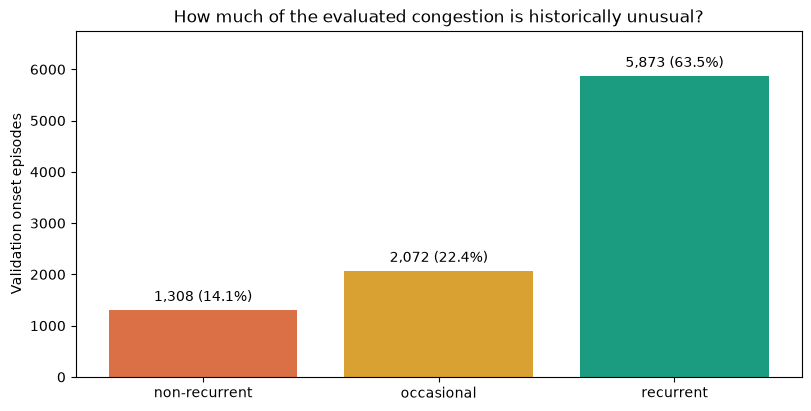

In [4]:
onsets=reference.loc[reference.onset].copy().reset_index(drop=True)
lookup=reference.set_index(sf.KEY)
warning_keys=pd.MultiIndex.from_arrays([onsets.station.to_numpy(),(onsets.timestamp-pd.Timedelta(minutes=sf.MIN_LEAD_MIN)).to_numpy()])
warning=lookup.reindex(warning_keys)
for column in ["typical_congestion_30","speed","real","jam_distance_down","min_speed_down","minutes_since_slow","downstream_speed"]:
    onsets[column+" at warning"]=warning[column].to_numpy()
onsets["recurrence"]=onsets["typical_congestion_30 at warning"]
onsets["group"]=pd.cut(onsets.recurrence,[-np.inf,*RECURRENCE_CUTS,np.inf],labels=GROUPS,right=False)
classified=onsets.group.notna()
recurrence_counts=onsets.loc[classified,"group"].value_counts().reindex(GROUPS).to_frame("onsets")
recurrence_counts["share"]=recurrence_counts.onsets/recurrence_counts.onsets.sum()
display(recurrence_counts.round(4))
print("Onsets without recurrence classification:",int((~classified).sum()))
fig,ax=plt.subplots(figsize=(8,4),layout="constrained")
bars=ax.bar(GROUPS,recurrence_counts.onsets,color=[GROUP_COLORS[g] for g in GROUPS])
ax.bar_label(bars,labels=[f"{n:,} ({s:.1%})" for n,s in zip(recurrence_counts.onsets,recurrence_counts.share)],padding=4)
ax.set(ylabel="Validation onset episodes",title="How much of the evaluated congestion is historically unusual?")
ax.margins(y=.15)
fig.savefig(OUT/"recurrence_groups.png",dpi=160,bbox_inches="tight")
plt.show()

## 4. Exact matched-budget operating points

Sweep all relevant probability breakpoints, including immediately-above cases for tied scores. False-warning episodes are counted exactly as contiguous wrong-alert stretches at each station; missing times or unknown outcomes break a stretch. The algorithm uses active rows minus active adjacent pairs, so it does not assume monotone episode counts.

The selected policies maximize global early-onset detection subject to each budget. They are tuned and evaluated on the same pooled development predictions and can be optimistic. They are exploratory policies, not an independent later-quarter or holdout evaluation. An episode-only budget can favor long continuous alerts; inspect wrong-alert duration alongside it.

Exact warning-budget sweep: Timetable
Exact warning-budget sweep: Random Forest
Exact warning-budget sweep: Transformer
Exact warning-budget sweep: Boosted trees (29)


,model,budget_type,threshold,caught_15min,false_episodes_per_day,wrong_alert_hours_per_day
0,Timetable,episodes,0.4681,0.5762,19.9680,10.0716
1,Timetable,duration,0.7333,0.3362,8.9733,3.9984
2,Random Forest,episodes,0.6951,0.2644,19.9867,2.3062
3,Random Forest,duration,0.5338,0.4829,28.3040,3.9987
4,Transformer,episodes,0.6993,0.5031,20.0000,3.0347
5,Transformer,duration,0.6175,0.5788,24.3413,3.9980
6,Boosted trees (29),episodes,0.6929,0.4622,19.9973,2.7102
7,Boosted trees (29),duration,0.5792,0.5718,26.5627,3.9991


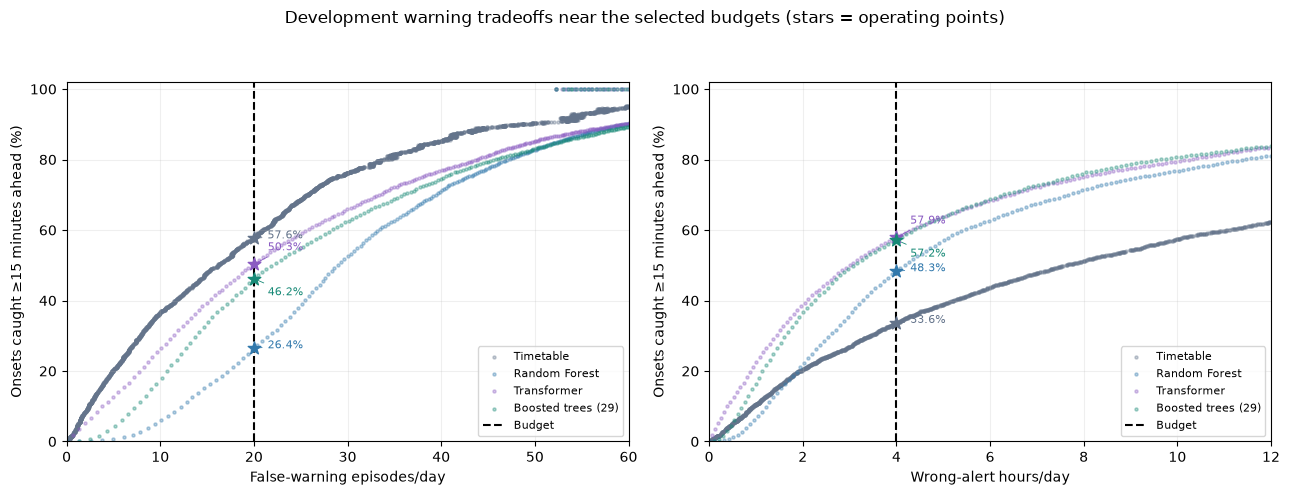

In [5]:
operating_parts,curve_parts,verification=[] ,[],[]
for label in WHO:
    print("Exact warning-budget sweep:",label,flush=True)
    sweep=ExactWarningSweep(reference,reference[label].to_numpy(),min_lead=sf.MIN_LEAD_MIN,window_minutes=sf.WINDOW_MIN)
    policy,curve=sweep.operating_points(EPISODE_BUDGET,HOURS_BUDGET)
    for row in policy.itertuples():
        measured=sf.alert_metrics(reference,reference[label].to_numpy(),row.threshold)
        assert np.isclose(measured["caught ≥15 min"],row.caught_15min)
        assert np.isclose(measured["false alarms / day"],row.false_episodes_per_day)
        assert np.isclose(measured["wrong-alert hours / day"],row.wrong_alert_hours_per_day)
        verification.append(dict(model=label,budget_type=row.budget_type,exact_matches_shared_scorer=True))
        onsets[f"lead::{label}::{row.budget_type}"]=warning_leads(reference,reference[label],onsets,row.threshold,sf.WINDOW_MIN)
    operating_parts.append(policy.assign(model=label))
    curve_parts.append(curve.assign(model=label))
operating=pd.concat(operating_parts,ignore_index=True)
curves=pd.concat(curve_parts,ignore_index=True)
display(operating[["model","budget_type","threshold","caught_15min","false_episodes_per_day","wrong_alert_hours_per_day"]].round(4))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,column,budget,xlabel in zip(axes,["false_episodes_per_day","wrong_alert_hours_per_day"],
    [EPISODE_BUDGET,HOURS_BUDGET],["False-warning episodes/day","Wrong-alert hours/day"]):
    for label in WHO:
        part=curves.loc[curves.model.eq(label)].sort_values("threshold")
        ax.scatter(part[column],100*part.caught_15min,s=5,alpha=.35,color=COLORS[label],label=label)
    ax.axvline(budget,linestyle="--",color="black",label="Budget")
    selected_type="episodes" if column=="false_episodes_per_day" else "duration"
    for point in operating.loc[operating.budget_type.eq(selected_type)].itertuples():
        ax.scatter(getattr(point,column),100*point.caught_15min,s=90,marker="*",color=COLORS[point.model],zorder=5)
        text_offset=10 if point.model=="Transformer" else -12 if point.model=="Boosted trees (29)" else 0
        ax.annotate(f"{point.caught_15min:.1%}",(getattr(point,column),100*point.caught_15min),xytext=(10,text_offset),textcoords="offset points",fontsize=8,color=COLORS[point.model],arrowprops=dict(arrowstyle="-",color=COLORS[point.model],lw=.6))
    ax.set(xlabel=xlabel,ylabel="Onsets caught ≥15 minutes ahead (%)",ylim=(0,102),xlim=(0,3*budget))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8,loc="lower right")
fig.suptitle("Development warning tradeoffs near the selected budgets (stars = operating points)")
fig.tight_layout(rect=[0,0,1,.93])
fig.tight_layout(rect=[0,0,1,.93])
fig.savefig(OUT/"matched_budget_tradeoffs.png",dpi=160,bbox_inches="tight")
plt.show()

## 5. Does performance on unusual jams differ from routine jams?

The event table reports ≥15-minute catch rates within recurrence groups, using the same globally selected budget policy for every group. Group AP instead uses currently uncongested, measured station-time rows grouped by their **current** training-only usual congestion rate. Its grouping time and denominator therefore differ from the onset table. AP is compared with each subgroup's own positive prevalence.

model                              Boosted trees (29)  ...  Transformer
budget_type group          onsets                      ...             
duration    all classified 9253                0.5742  ...       0.5813
            non-recurrent  1308                0.0390  ...       0.0612
            occasional     2072                0.2621  ...       0.3098
            recurrent      5873                0.8035  ...       0.7930
episodes    all classified 9253                0.4642  ...       0.5052
            non-recurrent  1308                0.0161  ...       0.0367
            occasional     2072                0.1462  ...       0.2206
            recurrent      5873                0.6761  ...       0.7100

[8 rows x 4 columns]

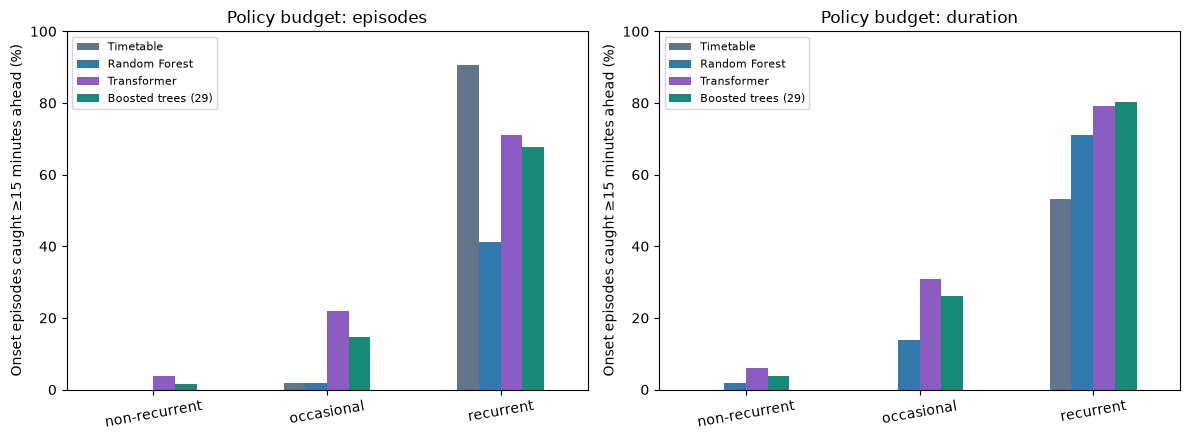

,group,model,n,positive_prevalence,AP
0,non-recurrent,Timetable,1330797,0.0069,0.0327
1,non-recurrent,Random Forest,1330797,0.0069,0.2684
2,non-recurrent,Transformer,1330797,0.0069,0.2576
3,non-recurrent,Boosted trees (29),1330797,0.0069,0.2666
4,occasional,Timetable,120964,0.1274,0.1897
5,occasional,Random Forest,120964,0.1274,0.4899
6,occasional,Transformer,120964,0.1274,0.5141
7,occasional,Boosted trees (29),120964,0.1274,0.5262
8,recurrent,Timetable,106866,0.4918,0.6586
9,recurrent,Random Forest,106866,0.4918,0.8529


In [6]:
catch_rows=[]
for budget_type in ["episodes","duration"]:
    for group in GROUPS+["all classified"]:
        part=onsets.loc[classified] if group=="all classified" else onsets.loc[onsets.group.eq(group)]
        for label in WHO:
            catch_rows.append(dict(budget_type=budget_type,group=group,model=label,onsets=len(part),
                caught_15min=(part[f"lead::{label}::{budget_type}"]>=sf.MIN_LEAD_MIN).mean()))
catch_rates=pd.DataFrame(catch_rows)
display(catch_rates.pivot(index=["budget_type","group","onsets"],columns="model",values="caught_15min").round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
for ax,budget_type in zip(axes,["episodes","duration"]):
    table=catch_rates.loc[catch_rates.budget_type.eq(budget_type)].pivot(index="group",columns="model",values="caught_15min").reindex(GROUPS)
    (100*table[WHO]).plot.bar(ax=ax,color=[COLORS[m] for m in WHO],rot=10)
    ax.set(title=f"Policy budget: {budget_type}",ylabel="Onset episodes caught ≥15 minutes ahead (%)",ylim=(0,100),xlabel="")
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUT/"catch_rates_by_recurrence.png",dpi=170,bbox_inches="tight")
plt.show()

ap_rows=[]
scored=reference.loc[primary]
row_group=pd.cut(scored.typical_congestion_30.fillna(0),[-np.inf,*RECURRENCE_CUTS,np.inf],labels=GROUPS,right=False)
for group in GROUPS:
    part=scored.loc[row_group.eq(group)]
    for label in WHO:
        ap_rows.append(dict(group=group,model=label,n=len(part),positive_prevalence=part.y.mean(),
                           AP=average_precision_score(part.y,part[label])))
group_ap=pd.DataFrame(ap_rows)
display(group_ap.round(4))

## 6. Where and when are jams missed?

Use the episode-budget policy for these breakdowns. Report support alongside catch rates; small groups can be unstable. Recurrence classification is a timing proxy, not an incident label. Station geometry and missing upstream/downstream coverage can affect what a detector can observe. These plots describe failure patterns, not causal explanations.

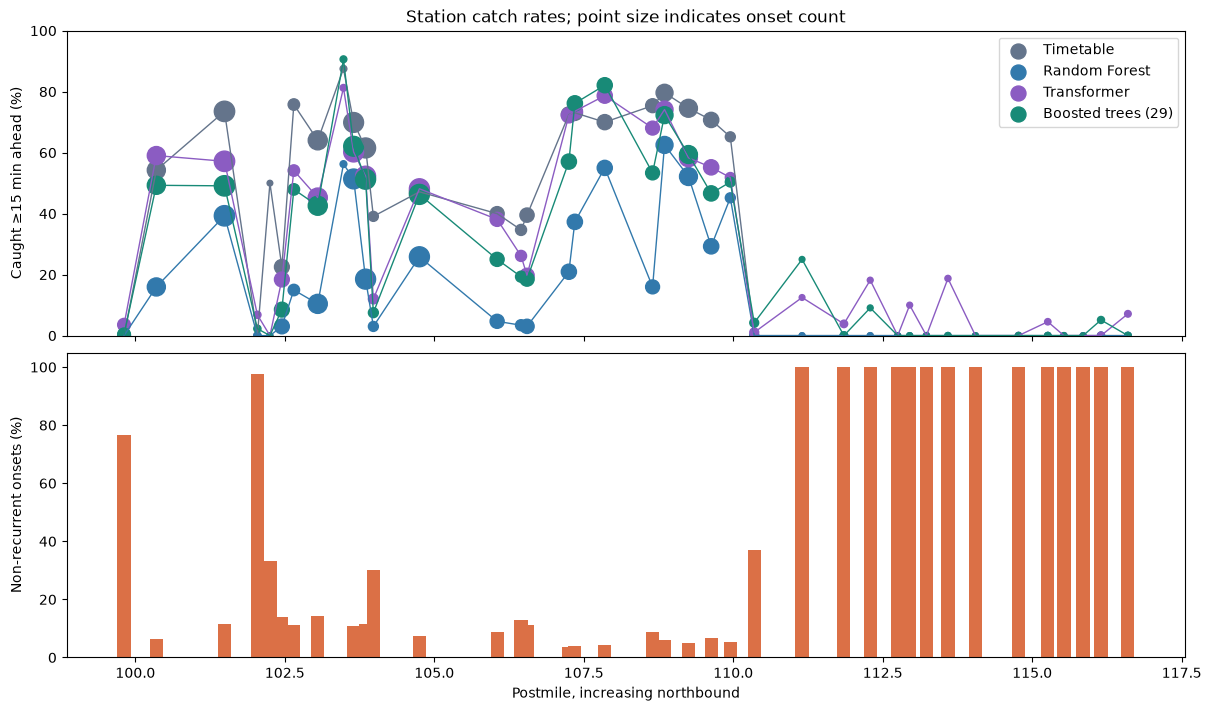

,station,onsets,pm,non_recurrent_share,caught_15min,name,model
140,1205517,52,111.850998,1.000,0.000,EUCLID 2,Boosted trees (29)
117,1205071,253,99.810997,0.767,0.004,JAMBOREE 2,Boosted trees (29)
138,1205473,95,110.350998,0.368,0.042,SOUTH 2,Boosted trees (29)
128,1205225,133,103.981003,0.301,0.075,GRAND 2,Boosted trees (29)
122,1205165,364,102.450996,0.140,0.085,S OF 55,Boosted trees (29)
132,1205330,329,106.551003,0.112,0.185,N OF 57,Boosted trees (29)
131,1205320,176,106.450996,0.131,0.193,LA VETA,Boosted trees (29)
130,1205303,320,106.051003,0.088,0.250,S OF 22,Boosted trees (29)
39,1205071,253,99.810997,0.767,0.000,JAMBOREE 2,Random Forest
60,1205473,95,110.350998,0.368,0.000,SOUTH 2,Random Forest


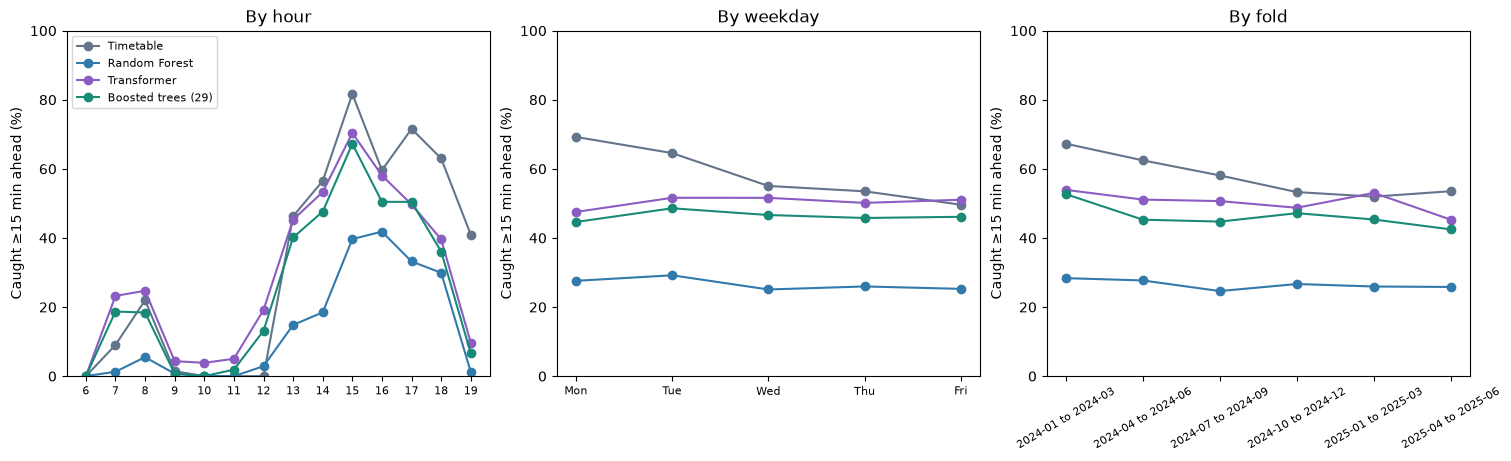

In [7]:
VIEW="episodes"
station_parts=[]
for label in WHO:
    part=onsets.loc[classified].assign(caught=lambda t:t[f"lead::{label}::{VIEW}"]>=sf.MIN_LEAD_MIN)
    table=part.groupby("station").agg(onsets=("onset","size"),pm=("pm","first"),
        non_recurrent_share=("group",lambda g:g.eq("non-recurrent").mean()),caught_15min=("caught","mean"))
    table["name"]=table.index.map(names)
    station_parts.append(table.reset_index().assign(model=label))
station_metrics=pd.concat(station_parts,ignore_index=True)
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,layout="constrained")
for label in WHO:
    part=station_metrics.loc[station_metrics.model.eq(label)].sort_values("pm")
    axes[0].plot(part.pm,100*part.caught_15min,color=COLORS[label],linewidth=1)
    axes[0].scatter(part.pm,100*part.caught_15min,s=15+200*part.onsets/part.onsets.max(),color=COLORS[label],label=label)
part=station_metrics.loc[station_metrics.model.eq(WHO[0])].sort_values("pm")
axes[1].bar(part.pm,100*part.non_recurrent_share,width=.22,color=GROUP_COLORS["non-recurrent"])
axes[0].set(ylabel="Caught ≥15 min ahead (%)",title="Station catch rates; point size indicates onset count",ylim=(0,100))
axes[0].legend()
axes[1].set(xlabel="Postmile, increasing northbound",ylabel="Non-recurrent onsets (%)")
fig.savefig(OUT/"station_failures.png",dpi=160,bbox_inches="tight")
plt.show()
display(station_metrics.loc[station_metrics.onsets.ge(50)].sort_values(["model","caught_15min"]).groupby("model").head(8).round(3))

onsets["hour"]=onsets.timestamp.dt.hour
onsets["weekday"]=onsets.timestamp.dt.day_name().str[:3]
time_rows=[]
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
for ax,(column,order) in zip(axes,[("hour",list(range(6,20))),("weekday",["Mon","Tue","Wed","Thu","Fri"]),("fold",sorted(reference.fold.unique()))]):
    for label in WHO:
        part=onsets.loc[classified].assign(caught=lambda t:t[f"lead::{label}::{VIEW}"]>=sf.MIN_LEAD_MIN)
        table=part.groupby(column).agg(onsets=("onset","size"),caught_15min=("caught","mean")).reindex(order)
        ax.plot(np.arange(len(order)),100*table.caught_15min,marker="o",color=COLORS[label],label=label)
        time_rows.append(table.reset_index().rename(columns={column:"slice"}).assign(model=label,slice_type=column))
    ax.set(xticks=np.arange(len(order)),xticklabels=[str(v) for v in order],ylim=(0,100),title="By "+column,ylabel="Caught ≥15 min ahead (%)")
    ax.tick_params(axis="x",rotation=30 if column=="fold" else 0,labelsize=8)
axes[0].legend(fontsize=8)
fig.savefig(OUT/"temporal_failures.png",dpi=170,bbox_inches="tight")
plt.show()
time_metrics=pd.concat(time_rows,ignore_index=True)

## 7. What traffic signals were visible before onset?

Compare local speed bands and whether a measured queue is represented by a downstream-jam distance <5 miles at t−15. The original features can interpret missing downstream readings as no detected jam; this flag is therefore an observation proxy, not proof that the whole road ahead was uncongested. Catch-rate associations do not identify why a jam formed.

,condition,onsets,caught_15min,model,factor
0,40–<50 mph,5265,0.5878,Timetable,speed band
1,50–<60 mph,3422,0.6087,Timetable,speed band
2,60+ mph,566,0.3127,Timetable,speed band
3,detected,5400,0.6446,Timetable,downstream jam
4,not detected,3853,0.4864,Timetable,downstream jam
5,40–<50 mph,5265,0.3814,Random Forest,speed band
6,50–<60 mph,3422,0.1283,Random Forest,speed band
7,60+ mph,566,0.0177,Random Forest,speed band
8,detected,5400,0.3348,Random Forest,downstream jam
9,not detected,3853,0.1684,Random Forest,downstream jam


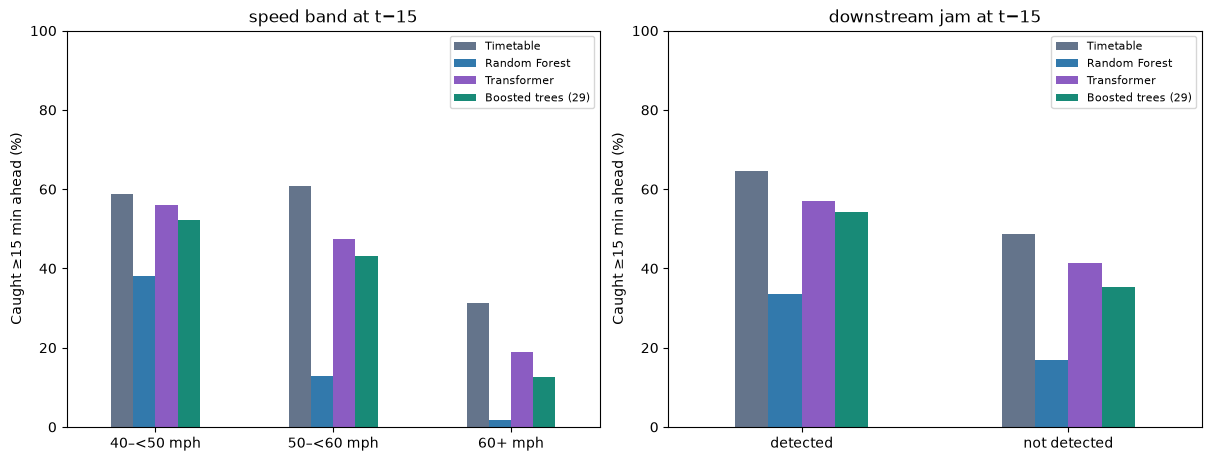

In [8]:
onsets["speed band"]=pd.cut(onsets["speed at warning"],[0,50,60,np.inf],labels=["40–<50 mph","50–<60 mph","60+ mph"],right=False)
onsets["downstream jam"]=np.where(onsets["jam_distance_down at warning"]<sf.DOWNSTREAM_MILES,"detected","not detected")
condition_rows=[]
for label in WHO:
    part=onsets.loc[classified].assign(caught=lambda t:t[f"lead::{label}::{VIEW}"]>=sf.MIN_LEAD_MIN)
    for factor in ["speed band","downstream jam"]:
        table=part.groupby(factor,observed=True).agg(onsets=("onset","size"),caught_15min=("caught","mean")).reset_index().rename(columns={factor:"condition"})
        condition_rows.append(table.assign(model=label,factor=factor))
conditions=pd.concat(condition_rows,ignore_index=True)
display(conditions.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
for ax,factor in zip(axes,["speed band","downstream jam"]):
    table=conditions.loc[conditions.factor.eq(factor)].pivot(index="condition",columns="model",values="caught_15min")
    (100*table[WHO]).plot.bar(ax=ax,color=[COLORS[m] for m in WHO],rot=0)
    ax.set(title=factor+" at t−15",ylabel="Caught ≥15 min ahead (%)",xlabel="",ylim=(0,100))
    ax.legend(fontsize=8)
fig.savefig(OUT/"warning_time_conditions.png",dpi=170,bbox_inches="tight")
plt.show()

## 8. Shared close-up examples

Choose missed and caught non-recurrent events using the Random Forest policy with a fixed random seed, then show **every available model on the same events**. The selection is an illustration anchored to Random Forest outcomes, not a representative performance sample for the transformer. The heatmaps show current corridor speeds; probability traces leave missing timestamps as gaps. Visible queues and abrupt changes suggest hypotheses, not verified incident causes.

The close-ups use the **4 wrong-alert hours/day** policy so that both caught and missed unusual examples can be shown. The station/time/condition breakdowns above use the episode-budget policy.


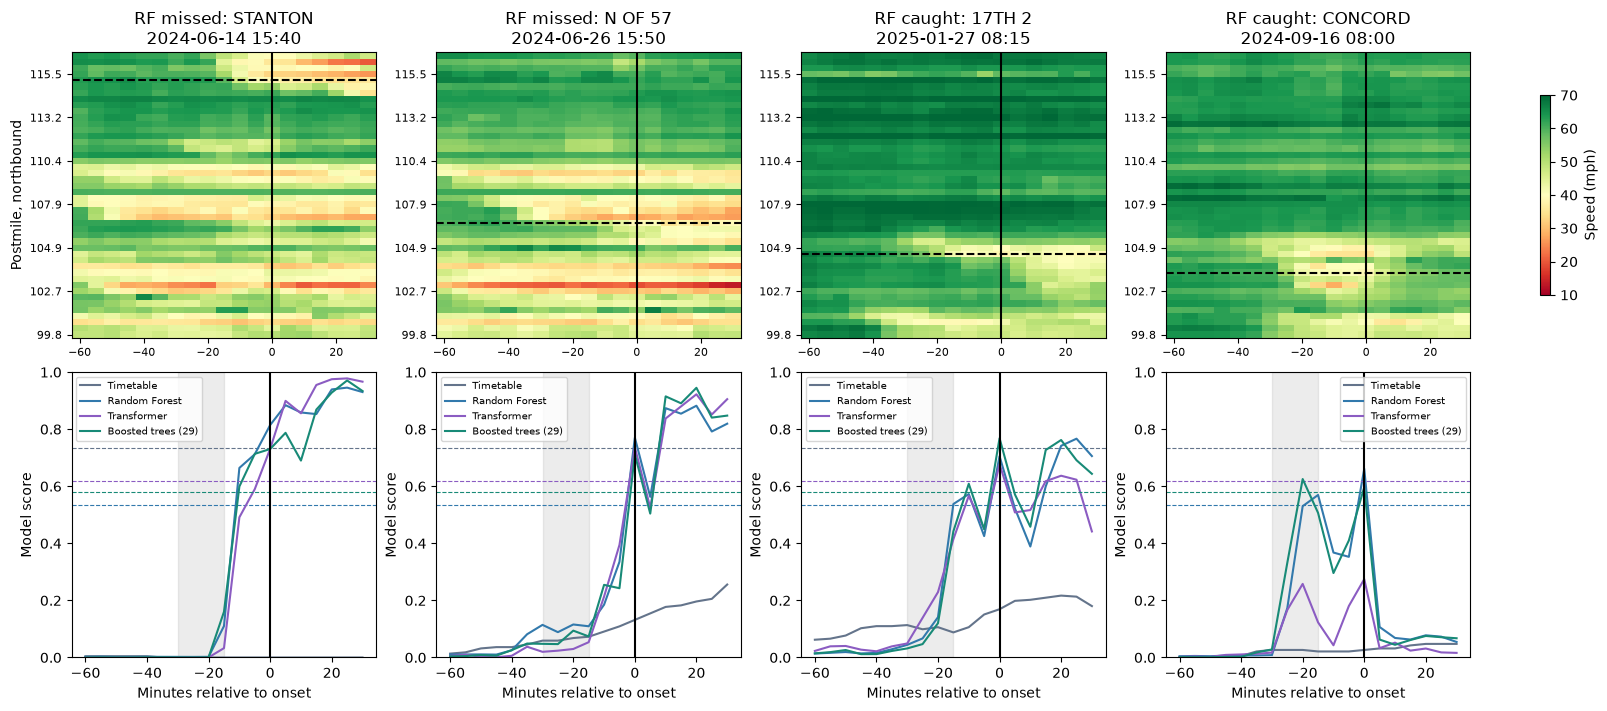

In [9]:
EXAMPLE_VIEW="duration"
unusual=onsets.loc[onsets.group.eq("non-recurrent")]
rng=np.random.default_rng(0)
examples=[]
rf_caught=unusual[f"lead::Random Forest::{EXAMPLE_VIEW}"].ge(sf.MIN_LEAD_MIN)
for outcome,part,number in [("RF missed",unusual.loc[~rf_caught],N_MISSED_EXAMPLES),("RF caught",unusual.loc[rf_caught],N_CAUGHT_EXAMPLES)]:
    if len(part):
        chosen=rng.choice(len(part),size=min(number,len(part)),replace=False)
        examples.extend((outcome,row) for _,row in part.iloc[chosen].iterrows())
road=reference.groupby("station").pm.first().sort_values()
speed=reference.set_index(sf.KEY).speed
if examples:
    fig,axes=plt.subplots(2,len(examples),figsize=(4*len(examples),7),squeeze=False,layout="constrained")
    image=None
    for column,(outcome,event) in enumerate(examples):
        times=pd.date_range(event.timestamp-pd.Timedelta(minutes=60),event.timestamp+pd.Timedelta(minutes=30),freq="5min")
        grid=speed.reindex(pd.MultiIndex.from_product([road.index,times])).to_numpy().reshape(len(road),len(times))
        ax=axes[0,column]
        image=ax.imshow(grid,origin="lower",aspect="auto",cmap="RdYlGn",vmin=10,vmax=70,extent=[-62.5,32.5,-.5,len(road)-.5])
        ax.axhline(road.index.get_loc(event.station),linestyle="--",color="black")
        ax.axvline(0,color="black")
        ticks=np.arange(0,len(road),7)
        ax.set(yticks=ticks,yticklabels=[f"{p:.1f}" for p in road.iloc[ticks]],title=f"{outcome}: {names.get(event.station,event.station)}\n{event.timestamp:%Y-%m-%d %H:%M}")
        ax.tick_params(labelsize=8)
        ax=axes[1,column]
        keys=pd.MultiIndex.from_product([[event.station],times])
        for label in WHO:
            q=lookup[label].reindex(keys)
            threshold=operating.loc[operating.model.eq(label)&operating.budget_type.eq(EXAMPLE_VIEW),"threshold"].iloc[0]
            ax.plot(np.arange(-60,31,5),q.to_numpy(),color=COLORS[label],label=label)
            ax.axhline(threshold,color=COLORS[label],linestyle="--",linewidth=.8)
        ax.axvspan(-30,-sf.MIN_LEAD_MIN,color="gray",alpha=.15)
        ax.axvline(0,color="black")
        ax.set(ylim=(0,1),xlabel="Minutes relative to onset",ylabel="Model score")
        ax.legend(fontsize=7)
    axes[0,0].set_ylabel("Postmile, northbound")
    fig.colorbar(image,ax=axes[0,:].tolist(),shrink=.7,label="Speed (mph)")
    fig.savefig(OUT/"unusual_onset_examples.png",dpi=150,bbox_inches="tight")
    plt.show()

## 9. Export measured findings and input availability

All subgroup statements must be tied to the model inputs actually available in this run. A missing transformer export is a missing analysis input, not evidence about its performance. Reusing old summary scores cannot recover which particular unusual jams it caught. Add the export path and rerun this notebook to obtain exactly the same diagnostics for it.

These are retrospective, pooled-development results. A next-quarter threshold-selection experiment is needed for a less optimistic estimate of a deployed budget policy. No model, feature, or threshold decision here uses the final holdout.

In [10]:
operating.to_csv(OUT/"matched_budget_policies.csv",index=False)
curves.to_csv(OUT/"warning_curve_sample.csv",index=False)
catch_rates.to_csv(OUT/"catch_rates_by_recurrence.csv",index=False)
group_ap.to_csv(OUT/"AP_by_recurrence.csv",index=False)
fold_ap.to_csv(OUT/"fold_AP_checks.csv",index=False)
station_metrics.to_csv(OUT/"station_errors.csv",index=False)
time_metrics.to_csv(OUT/"temporal_errors.csv",index=False)
conditions.to_csv(OUT/"warning_time_conditions.csv",index=False)
recurrence_counts.to_csv(OUT/"recurrence_counts.csv")
onsets.to_parquet(OUT/"onset_diagnostics.parquet",index=False)
pd.DataFrame(pending,columns=["model","status"]).to_csv(OUT/"pending_inputs.csv",index=False)
manifest=dict(models_analyzed=WHO,pending=pending,input_provenance=input_provenance,
    shared_code_sha256=shared_hash,context_signature=context_signature,
    episode_budget=EPISODE_BUDGET,hours_budget=HOURS_BUDGET,recurrence_cuts=RECURRENCE_CUTS,
    validation_rows=len(reference),onsets=len(onsets),classified_onsets=int(classified.sum()),
    unclassified_onsets=int((~classified).sum()),min_lead_minutes=sf.MIN_LEAD_MIN,
    source="saved validation predictions; no retraining",holdout_used=False,
    threshold_selection="exact breakpoints, pooled development; not independent evaluation",
    shared_scorer_verification=verification)
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
for label in WHO:
    print("\n"+label)
    for budget_type in ["episodes","duration"]:
        row=operating.loc[operating.model.eq(label)&operating.budget_type.eq(budget_type)].iloc[0]
        rare=catch_rates.loc[catch_rates.model.eq(label)&catch_rates.budget_type.eq(budget_type)&catch_rates.group.eq("non-recurrent")].iloc[0]
        print(f"  {budget_type}: threshold {row.threshold:.5f}, global early catch {row.caught_15min:.1%}, "
              f"unusual-jam early catch {rare.caught_15min:.1%}; false episodes/day {row.false_episodes_per_day:.2f}, "
              f"wrong-alert hours/day {row.wrong_alert_hours_per_day:.2f}")
print("\nPending input:",[r["model"] for r in pending])
print("Saved:",OUT)


Timetable
  episodes: threshold 0.46809, global early catch 57.6%, unusual-jam early catch 0.0%; false episodes/day 19.97, wrong-alert hours/day 10.07
  duration: threshold 0.73333, global early catch 33.6%, unusual-jam early catch 0.0%; false episodes/day 8.97, wrong-alert hours/day 4.00

Random Forest
  episodes: threshold 0.69507, global early catch 26.4%, unusual-jam early catch 0.0%; false episodes/day 19.99, wrong-alert hours/day 2.31
  duration: threshold 0.53385, global early catch 48.3%, unusual-jam early catch 1.8%; false episodes/day 28.30, wrong-alert hours/day 4.00

Transformer
  episodes: threshold 0.69928, global early catch 50.3%, unusual-jam early catch 3.7%; false episodes/day 20.00, wrong-alert hours/day 3.03
  duration: threshold 0.61751, global early catch 57.9%, unusual-jam early catch 6.1%; false episodes/day 24.34, wrong-alert hours/day 4.00

Boosted trees (29)
  episodes: threshold 0.69291, global early catch 46.2%, unusual-jam early catch 1.6%; false episodes